# Laboratorio · Predecir propinas con Python
**Regresión lineal · Ejercicio individual**

**Dataset:** `tips.csv`, 244 cuentas de restaurante. [Ver dataset en Kaggle](https://www.kaggle.com/datasets/sakshisatre/tips-dataset).

**Problema:** estimar `tip` (propina en USD) a partir de `total_bill` (cuenta en USD) y después comprobar si `size` (número de personas) aporta valor.

**Instrucciones:** ejecutar las actividades en orden, completar las celdas de código y responder las preguntas con resultados propios. El archivo CSV debe estar junto al notebook.

## 01 · Explorar el CSV
**Objetivo.** Cargar `tips.csv` y mostrar **cinco filas**, dimensiones, valores faltantes y resumen numérico.

*Pista:* `pd.read_csv()`, `.head()`, `.shape`, `.isna().sum()`, `.describe()`.

**Resultado esperado:** Una tabla y el resumen inicial.

In [1]:
# Completar aquí

import pandas as pd

# Cargar el archivo CSV
datos = pd.read_csv("tips.csv")

# Mostrar las primeras cinco filas
print("Primeras cinco filas:")
display(datos.head())

# Mostrar las dimensiones
print("Dimensiones del dataset:", datos.shape)

# Comprobar valores faltantes
print("Valores faltantes:")
print(datos.isna().sum())

# Mostrar un resumen estadístico
print("Resumen estadístico:")
display(datos.describe())


Primeras cinco filas:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Dimensiones del dataset: (244, 7)
Valores faltantes:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Resumen estadístico:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 02 · Separar entradas y objetivo
**Objetivo.** Crear `X` con la cuenta total (`total_bill`) y `y` con la propina real (`tip`). Mostrar sus primeras filas y dimensiones.

*Pista:* `datos[["total_bill"]]` devuelve una tabla; `datos["tip"]` devuelve la serie objetivo.

**Resultado esperado:** Entradas y objetivos claramente identificados.

In [2]:
# Completar aquí

# Separar las variables de entrada y objetivo
X = datos[["total_bill"]]
y = datos["tip"]

# Mostrar las primeras cinco filas de X
print("Primeras filas de X:")
display(X.head())

# Mostrar los primeros cinco valores de y
print("Primeros valores de y:")
display(y.head())

# Mostrar las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Primeras filas de X:


,total_bill
0,16.99
1,10.34
2,21.01
3,23.68
4,24.59


Primeros valores de y:


0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

Dimensiones de X: (244, 1)
Dimensiones de y: (244,)


## 03 · Crear entrenamiento y prueba
**Objetivo.** Reservar el 25 % de los registros para evaluar, usando `random_state=42`. Mostrar cuántas filas quedan en cada conjunto.

*Pista:* `train_test_split()` del módulo `sklearn.model_selection`.

**Resultado esperado:** Tamaños de `X_train`, `X_test`, `y_train`, `y_test`.

In [3]:
# Completar aquí

from sklearn.model_selection import train_test_split

# Dividir los datos: 75% entrenamiento y 25% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Mostrar las dimensiones
print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)

print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de y_test:", y_test.shape)


Dimensiones de X_train: (183, 1)
Dimensiones de X_test: (61, 1)
Dimensiones de y_train: (183,)
Dimensiones de y_test: (61,)


## 04 · Entrenar y predecir
**Objetivo.** Crear una regresión, ajustarla con entrenamiento y predecir las propinas del conjunto de prueba. Mostrar cinco predicciones.

*Pista:* `LinearRegression()`, `.fit()`, `.predict()`.

**Resultado esperado:** Cinco importes estimados.

In [4]:
# Completar aquí

from sklearn.linear_model import LinearRegression

# Crear el modelo de regresión lineal
modelo = LinearRegression()

# Entrenar el modelo con los datos de entrenamiento
modelo.fit(X_train, y_train)

# Predecir las propinas del conjunto de prueba
y_pred = modelo.predict(X_test)

# Mostrar las primeras cinco predicciones
print("Primeras cinco predicciones:")
print(y_pred[:5])


Primeras cinco predicciones:
[3.03019394 1.82116362 3.54772457 3.69434001 2.28398699]


## 05 · Evaluar los errores
**Objetivo.** Calcular **MAE, MSE, RMSE y R²** sobre los datos de prueba e imprimir sus valores.

*Pista:* `sklearn.metrics`; para RMSE se puede usar `mse ** 0.5`.

**Resultado esperado:** Cuatro indicadores numéricos.

In [5]:
# Completar aquí

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calcular el error absoluto medio
mae = mean_absolute_error(y_test, y_pred)

# Calcular el error cuadrático medio
mse = mean_squared_error(y_test, y_pred)

# Calcular la raíz del error cuadrático medio
rmse = mse ** 0.5

# Calcular el coeficiente de determinación
r2 = r2_score(y_test, y_pred)

# Mostrar los resultados
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


MAE: 0.6522
MSE: 0.7449
RMSE: 0.8631
R²: 0.4401


## 06 · Graficar datos y predicción
**Objetivo.** Construir una tabla de cinco valores reales y predichos. Dibujar los puntos reales y la recta del modelo, con nombres en los ejes y leyenda.

*Pista:* `pd.DataFrame()`, `plt.scatter()`, `plt.plot()`; ordenar X solo para dibujar la línea.

**Resultado esperado:** Tabla comparativa y gráfico.

,Cuenta (USD),Propina real (USD),Propina predicha (USD)
0,19.82,3.18,3.03
1,8.77,2.00,1.82
2,24.55,2.00,3.55
3,25.89,5.16,3.69
4,13.00,2.00,2.28


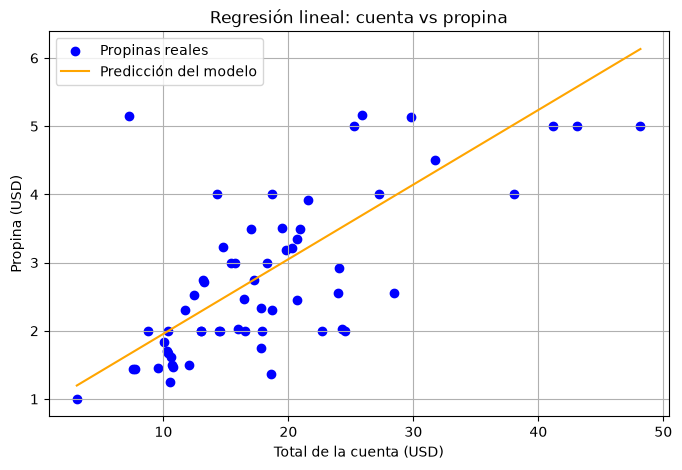

In [6]:
# Completar aquí

import matplotlib.pyplot as plt

# Crear una tabla con cinco valores reales y predichos
tabla = pd.DataFrame({
    "Cuenta (USD)": X_test["total_bill"].to_numpy()[:5],
    "Propina real (USD)": y_test.to_numpy()[:5],
    "Propina predicha (USD)": y_pred[:5]
})

# Mostrar la tabla con dos decimales
display(tabla.round(2))

# Ordenar las cuentas para dibujar la recta
orden = X_test["total_bill"].argsort()

# Crear el gráfico
plt.figure(figsize=(8, 5))

# Dibujar los puntos reales
plt.scatter(
    X_test["total_bill"],
    y_test,
    color="blue",
    label="Propinas reales"
)

# Dibujar la recta de predicción
plt.plot(
    X_test["total_bill"].iloc[orden],
    y_pred[orden],
    color="orange",
    label="Predicción del modelo"
)

# Agregar títulos y leyenda
plt.xlabel("Total de la cuenta (USD)")
plt.ylabel("Propina (USD)")
plt.title("Regresión lineal: cuenta vs propina")
plt.legend()
plt.grid(True)

# Mostrar el gráfico
plt.show()


## 07 · Inspeccionar residuos
**Objetivo.** Calcular `real − predicho`; graficar los residuos contra las predicciones, con una línea horizontal en cero.

*Pista:* `.to_numpy()`, `plt.scatter()`, `plt.axhline(0)`.

**Resultado esperado:** Gráfico de residuos.

Primeros cinco residuos:
[ 0.14980606  0.17883638 -1.54772457  1.46565999 -0.28398699]


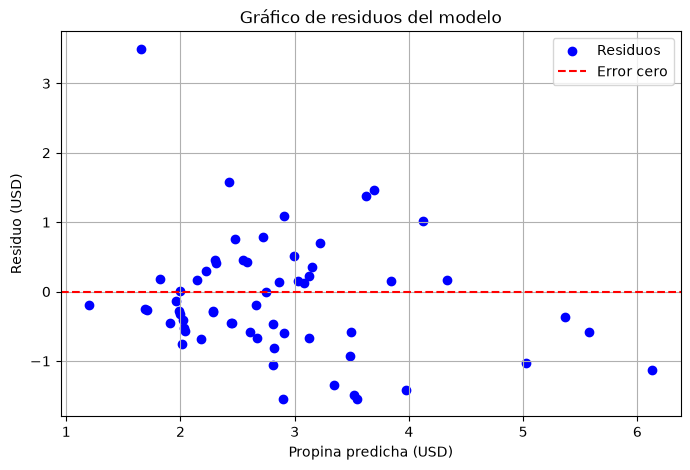

In [7]:
# Completar aquí

# Calcular los residuos: real - predicho
residuos = y_test.to_numpy() - y_pred

# Mostrar los primeros cinco residuos
print("Primeros cinco residuos:")
print(residuos[:5])

# Crear el gráfico
plt.figure(figsize=(8, 5))

# Graficar residuos contra predicciones
plt.scatter(
    y_pred,
    residuos,
    color="blue",
    label="Residuos"
)

# Dibujar una línea horizontal en cero
plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Error cero"
)

# Agregar nombres y título
plt.xlabel("Propina predicha (USD)")
plt.ylabel("Residuo (USD)")
plt.title("Gráfico de residuos del modelo")
plt.legend()
plt.grid(True)

# Mostrar el gráfico
plt.show()


## 08 · Comparar una y dos entradas
**Objetivo.** Entrenar un segundo modelo usando `total_bill` y `size` juntos. Comparar **MAE, RMSE y R²** con el modelo inicial.

*Pista:* Definir `X2` con dos columnas y repetir la partición con el mismo `random_state`.

**Resultado esperado:** Comparación numérica de ambos modelos.

In [8]:
# Completar aquí

# Crear las entradas del segundo modelo
X2 = datos[["total_bill", "size"]]

# Separar los datos en entrenamiento y prueba
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y,
    test_size=0.25,
    random_state=42
)

# Crear y entrenar el segundo modelo
modelo2 = LinearRegression()
modelo2.fit(X2_train, y2_train)

# Realizar las predicciones
y2_pred = modelo2.predict(X2_test)

# Calcular las métricas del segundo modelo
mae2 = mean_absolute_error(y2_test, y2_pred)
mse2 = mean_squared_error(y2_test, y2_pred)
rmse2 = mse2 ** 0.5
r2_2 = r2_score(y2_test, y2_pred)

# Comparar ambos modelos
comparacion = pd.DataFrame({
    "Modelo": ["Una entrada", "Dos entradas"],
    "MAE": [mae, mae2],
    "RMSE": [rmse, rmse2],
    "R2": [r2, r2_2]
})

display(comparacion.round(4))


,Modelo,MAE,RMSE,R2
0,Una entrada,0.6522,0.8631,0.4401
1,Dos entradas,0.6734,0.8799,0.4180


## Preguntas de desarrollo
Responder con los resultados obtenidos y, cuando corresponda, hacer referencia a los gráficos.

1. ¿Qué información contiene `X` y cuál es el objetivo `y`? ¿Qué cambia en la entrada cuando se agrega `size`?
2. ¿Cómo interpretar el MAE del primer modelo en **dólares de propina**? Dar un ejemplo de su significado.
3. ¿Qué diferencia existe entre MAE y RMSE? ¿Qué sugiere que RMSE sea mayor?
4. ¿Qué representa el R² obtenido? Explicar por qué **no** es un porcentaje de predicciones correctas.
5. ¿Qué se observa en el gráfico de residuos? ¿Hay valores especialmente alejados de cero?
6. ¿El modelo con dos entradas mejora los resultados en test? Justificar con MAE, RMSE y R² y proponer una explicación posible.

### Respuestas

**1.**
La variable `X` contiene los valores de `total_bill`, que corresponden al monto total de las cuentas del restaurante en dólares. Esta información se utiliza como entrada para entrenar el modelo de regresión lineal. Por otra parte, la variable `y` contiene los valores de `tip`, que representan las propinas reales y constituyen el objetivo que queremos predecir.

Al agregar `size`, la entrada pasa de tener una característica a tener dos: el total de la cuenta (`total_bill`) y la cantidad de personas en la mesa (`size`). De esta forma, el segundo modelo puede considerar ambas variables para estimar la propina, mientras que el objetivo `y` sigue siendo el mismo.

**2.**
El MAE del primer modelo fue de aproximadamente 0.6522 dólares, lo que significa que las propinas predichas presentan una diferencia absoluta promedio de alrededor de 65 centavos respecto a las propinas reales en el conjunto de prueba.

Por ejemplo, si un cliente deja una propina real de $4.00 y el modelo predice $3.35, el error absoluto sería de $0.65. Esto permite comprender que el MAE representa cuánto se equivoca el modelo en promedio, sin considerar si predice por encima o por debajo del valor real.

**3.**
La principal diferencia entre MAE y RMSE es que el MAE calcula el promedio de los errores absolutos, mientras que el RMSE eleva los errores al cuadrado antes de calcular su promedio y obtener la raíz cuadrada. Por esta razón, el RMSE da mayor importancia a los errores grandes.

En nuestro primer modelo obtuvimos un MAE de 0.6522 y un RMSE de 0.8631 dólares. Que el RMSE sea mayor sugiere que existen algunas predicciones con errores relativamente grandes que aumentan esta métrica. Esto indica que, aunque el error absoluto promedio es de aproximadamente 65 centavos, algunas predicciones pueden alejarse considerablemente de las propinas reales.

**4.**
El R² obtenido en el primer modelo fue de aproximadamente 0.4401, lo que significa que el modelo logra explicar cerca del 44.01 % de la variabilidad de las propinas en el conjunto de prueba utilizando el monto total de la cuenta (`total_bill`) como variable de entrada. Esto indica que existe una relación entre ambas variables, aunque una parte importante de la variabilidad de las propinas no es explicada por el modelo.

El R² no representa un porcentaje de predicciones correctas porque no cuenta cuántas predicciones coinciden con los valores reales. En cambio, mide qué tan bien el modelo explica las variaciones de los datos respecto a utilizar su promedio como referencia. Por lo tanto, un R² de 0.4401 no significa que el modelo acertó el 44.01 % de las predicciones, sino que explica aproximadamente esa proporción de la variabilidad observada.

**5.**
En el gráfico de residuos se observa que los errores se distribuyen tanto por encima como por debajo de la línea horizontal en cero. Esto significa que el modelo en algunos casos subestima las propinas y en otros las sobreestima. Aunque varias predicciones presentan errores relativamente pequeños, también existen algunos valores bastante alejados de cero.

Por ejemplo, encontramos un residuo positivo de aproximadamente 3.50 dólares, correspondiente a una propina real de $5.15 que el modelo había estimado en $1.65. También existen residuos negativos cercanos a −1.55 dólares.

Esto indica que, aunque el modelo logra identificar una tendencia general entre el monto de la cuenta y la propina, no consigue explicar completamente el comportamiento de los clientes, ya que pueden existir otros factores que influyan en las propinas.

**6.**
El modelo con dos entradas (`total_bill` y `size`) no logró mejorar los resultados en el conjunto de prueba respecto al modelo que utiliza solamente `total_bill`.

El primer modelo obtuvo un MAE de 0.6522, un RMSE de 0.8631 y un R² de 0.4401. En cambio, el segundo modelo obtuvo un MAE de 0.6734, un RMSE de 0.8799 y un R² de 0.4180. Esto demuestra que, al agregar la variable `size`, los errores aumentaron ligeramente y la capacidad del modelo para explicar la variabilidad de las propinas disminuyó.

Una posible explicación es que la cantidad de personas en la mesa no aporta suficiente información adicional para mejorar las predicciones, ya que parte de esa información podría estar relacionada con el monto total de la cuenta. Por lo tanto, podemos concluir que agregar más variables a un modelo no siempre garantiza mejores resultados.